# 04 · UCI ElectricityLoadDiagrams 2011–2014 – normal power load

**Utility for the City Brain: high** · Domain: power · Incident types: `power_problem`

> Real electricity consumption of 370 clients in Portugal every 15 min: the normal daily curve and noise level that a `power_load` sensor should show.

| | |
|---|---|
| **Source** | UCI Machine Learning Repository, dataset 321 |
| **Licence** | CC BY 4.0 (cite the UCI dataset) |
| **In this repo** | Sample: year 2013, the aggregate of all 370 clients + 6 single clients (`data/power/uci-load/uci_2013_sample.csv.gz`) |
| **Get it** | https://archive.ics.uci.edu/dataset/321/electricityloaddiagrams20112014 (711 MB, `;` separator, `,` decimals) |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

The original file has one column per client (`MT_001` … `MT_370`), average **kW per 15 min**, Portuguese local time. The sample keeps 2013 with `aggregate_kw` (sum of all clients, like a substation) and 6 individual clients.

In [2]:
u = pd.read_csv(path('power/uci-load/uci_2013_sample.csv.gz'), parse_dates=['timestamp'], index_col='timestamp')
print(u.shape); u.describe().round(0)

(35040, 7)


,aggregate_kw,MT_010,MT_100,MT_200,MT_300,MT_362,MT_124
count,35040.0,35040.0,35040.0,35040.0,35040.0,35040.0,35040.0
mean,222737.0,61.0,62.0,825.0,127.0,48697.0,276.0
std,81828.0,27.0,54.0,273.0,33.0,35396.0,128.0
min,4257.0,0.0,1.0,0.0,1.0,0.0,10.0
25%,146757.0,41.0,12.0,565.0,94.0,17100.0,153.0
50%,226017.0,57.0,57.0,891.0,135.0,41000.0,297.0
75%,268345.0,75.0,83.0,997.0,151.0,65100.0,364.0
max,452653.0,196.0,296.0,1579.0,228.0,181400.0,766.0


## 2. The daily curve

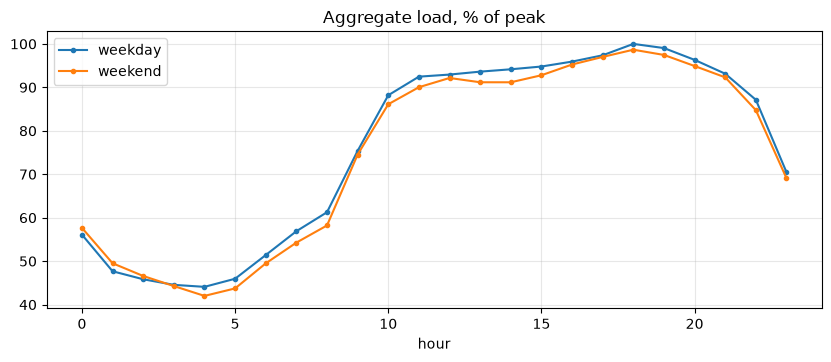

hour,0,3,6,9,12,15,18,21
weekday % of peak,56.0,45.0,51.0,75.0,93.0,95.0,100.0,93.0


In [3]:
u['hour'] = u.index.hour; u['weekend'] = u.index.day_of_week >= 5
prof = u.groupby(['weekend', 'hour']).aggregate_kw.median().unstack(0)
(prof / prof.max().max() * 100).plot(marker='.', title='Aggregate load, % of peak'); plt.legend(['weekday', 'weekend']); plt.show()
(prof[False] / prof[False].max() * 100).round(0).iloc[::3].to_frame('weekday % of peak').T

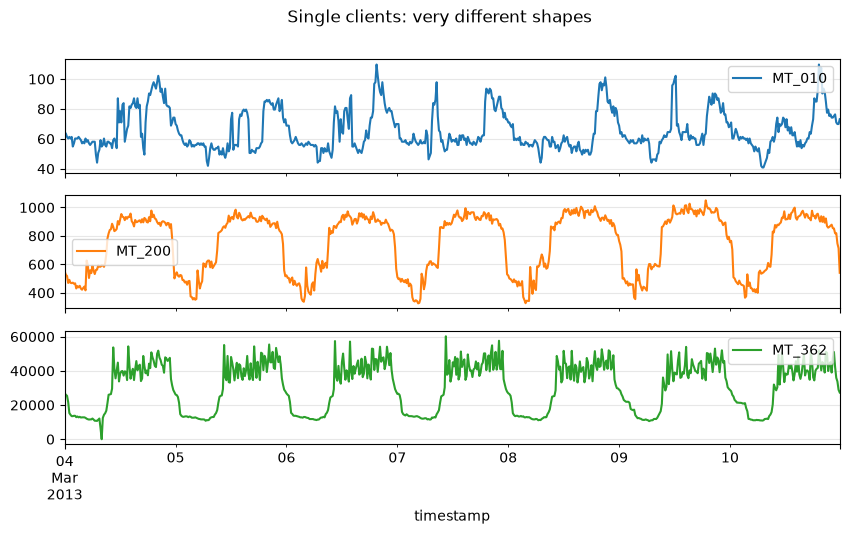

In [4]:
(u[['MT_010', 'MT_200', 'MT_362']].loc['2013-03-04':'2013-03-10']).plot(subplots=True, figsize=(10, 5), title='Single clients: very different shapes'); plt.show()

## 3. How noisy is normal load?

In [5]:
slot = u.index.strftime('%a %H:%M')
rows = {}
for c in ['aggregate_kw', 'MT_200', 'MT_300', 'MT_100', 'MT_362']:
    s = u[c].replace(0, np.nan)
    dev = s / s.groupby(slot).transform('median') - 1
    stp = s.pct_change().abs()
    rows[c] = {'deviation p5 %': dev.quantile(.05) * 100, 'deviation p95 %': dev.quantile(.95) * 100,
               'step p50 %': stp.median() * 100, 'step p99 %': stp.quantile(.99) * 100}
pd.DataFrame(rows).T.round(0)

,deviation p5 %,deviation p95 %,step p50 %,step p99 %
aggregate_kw,-14.0,46.0,2.0,15.0
MT_200,-13.0,30.0,3.0,28.0
MT_300,-15.0,23.0,4.0,33.0
MT_100,-32.0,106.0,6.0,67.0
MT_362,-35.0,116.0,5.0,80.0


In [6]:
day = u.aggregate_kw.resample('D').sum()
typ = day.groupby(day.index.day_of_week).transform('median')
odd = (day / typ - 1)
print('Days more than 20 % off typical:', (odd.abs() > .2).sum())
odd.sort_values().iloc[[0, 1, 2, -3, -2, -1]].mul(100).round(0).to_frame('% vs typical day')

Days more than 20 % off typical: 98


,% vs typical day
timestamp,
2013-12-25,-40.0
2013-01-01,-38.0
2013-03-31,-17.0
2013-07-06,51.0
2013-07-07,52.0
2013-07-09,53.0


Holidays (25 Dec, 1 Jan) look like a big drop and heat waves like a big rise: **normal events that a naive detector would call abnormal**.

## 4. What it means for the City Brain

| Use | How |
|---|---|
| **Mock** | Replay the aggregate (scaled to our substation) as `power_load`: real normal curve + real noise |
| **Detect** | A substation-level load can move ~16 % in 15 min normally (p99). `power_problem` needs a **same-time-of-day baseline** and a **second signal** (outage report, fire, Guardian), never load alone |
| **Scenarios** | Calm day; holiday / heat wave = "abnormal but not an incident" |

**Limits:** no outages or faults labelled; kW per 15 min (÷ 4 for kWh); Portugal, 2011–2014.